# Browsing the Planetary Computer with `stac_viewer`

`stac_viewer` turns any STAC catalog or API into something you can explore in a notebook: collections become attributes (`cat.sentinel_2_l2a`), each collection renders as a small card (footprint map, temporal extent, metadata), and `search()` returns items with a summary map. A bbox + date selector widget lets you pick a search region interactively.

This notebook uses Microsoft's Planetary Computer STAC API. No imagery is downloaded.

## Open the catalog

`browse()` accepts an API URL, a `catalog.json` path/URL or a pystac object. A trailing `/collections/` is stripped automatically, and extra keyword arguments go to `pystac_client.Client.open`. Here the `modifier` signs asset hrefs so they can be read later.

In [ ]:
%load_ext autoreload
%autoreload 2

import planetary_computer

from stac_viewer import browse

In [3]:
cat = browse(
    "https://planetarycomputer.microsoft.com/api/stac/v1/collections/",
    modifier=planetary_computer.sign_inplace,
)
cat

USGS 3DEP Lidar Classification,_3dep_lidar_classification
USGS 3DEP Lidar Point Cloud,_3dep_lidar_copc
USGS 3DEP Lidar Digital Surface Model,_3dep_lidar_dsm
USGS 3DEP Lidar Digital Terrain Model,_3dep_lidar_dtm
USGS 3DEP Lidar Digital Terrain Model (Native),_3dep_lidar_dtm_native
USGS 3DEP Lidar Height above Ground,_3dep_lidar_hag
USGS 3DEP Lidar Intensity,_3dep_lidar_intensity
USGS 3DEP Lidar Point Source,_3dep_lidar_pointsourceid
USGS 3DEP Lidar Returns,_3dep_lidar_returns
USGS 3DEP Seamless DEMs,_3dep_seamless
ALOS World 3D-30m,alos_dem


## Look at a collection

Collections are available by dot access (ids are turned into valid Python identifiers) or by bracket access with the original id. The card shows the spatial footprint, temporal extent, license, summaries and item assets.

In [4]:
cat.sentinel_2_l2a

key,format,title
AOT,COG,Aerosol optical thickness (AOT)
B01,COG,Band 1 - Coastal aerosol - 60m
B02,COG,Band 2 - Blue - 10m
B03,COG,Band 3 - Green - 10m
B04,COG,Band 4 - Red - 10m
B05,COG,Band 5 - Vegetation red edge 1 - 20m
B06,COG,Band 6 - Vegetation red edge 2 - 20m
B07,COG,Band 7 - Vegetation red edge 3 - 20m
B08,COG,Band 8 - NIR - 10m
B09,COG,Band 9 - Water vapor - 60m


## Interactive selector

`selector()` shows a map with a draggable bounding box plus start/end date fields. `search()` then uses the selection whenever you do not pass `bbox`/`datetime` explicitly. Drag a box on the map and pick dates, then run the search cell below.

In [16]:
sel = cat.sentinel_2_l2a.selector()
sel.bbox = [8.41, 47.30, 8.71, 47.49]  # preset bounding box
sel

Fallback for headless runs: set the selection in code. Dragging on the map does exactly the same.

In [17]:
items = cat.sentinel_2_l2a.search(sel, max_items=20)
items

id,date,cloud
S2C_MSIL2A_20261027T102121_R065_T32TMT_20261027T153610,2026-10-27 10:21,0%
S2B_MSIL2A_20261022T102049_R065_T32TMT_20261022T155522,2026-10-22 10:20,13%
S2A_MSIL2A_20261012T102911_R108_T32TMT_20261012T170607,2026-10-12 10:29,4%
S2B_MSIL2A_20261012T101949_R065_T32TMT_20261012T155603,2026-10-12 10:19,4%
S2B_MSIL2A_20261005T102859_R108_T32TMT_20261005T142235,2026-10-05 10:28,10%
S2C_MSIL2A_20260930T102821_R108_T32TMT_20260930T154858,2026-09-30 10:28,16%
S2A_MSIL2A_20260929T101741_R065_T32TMT_20260929T165907,2026-09-29 10:17,13%
S2C_MSIL2A_20260927T101801_R065_T32TMT_20260927T153810,2026-09-27 10:18,1%
S2B_MSIL2A_20260925T103019_R108_T32TMT_20260925T145653,2026-09-25 10:30,0%
S2A_MSIL2A_20260922T102701_R108_T32TMT_20260922T171012,2026-09-22 10:27,0%


In [28]:
settings = items.open_settings()
# set defaults for reproducible results - can also be set in open, but this is convenient for interactive demonstration
settings.set(assets=["B04", "B03", "B02"], resolution=25)

In [20]:
out = items.open(settings)

In [21]:
from dask.diagnostics.progress import ProgressBar

with ProgressBar():
    mosaic = out.median("time").compute()

[########################################] | 100% Completed | 38.85 s


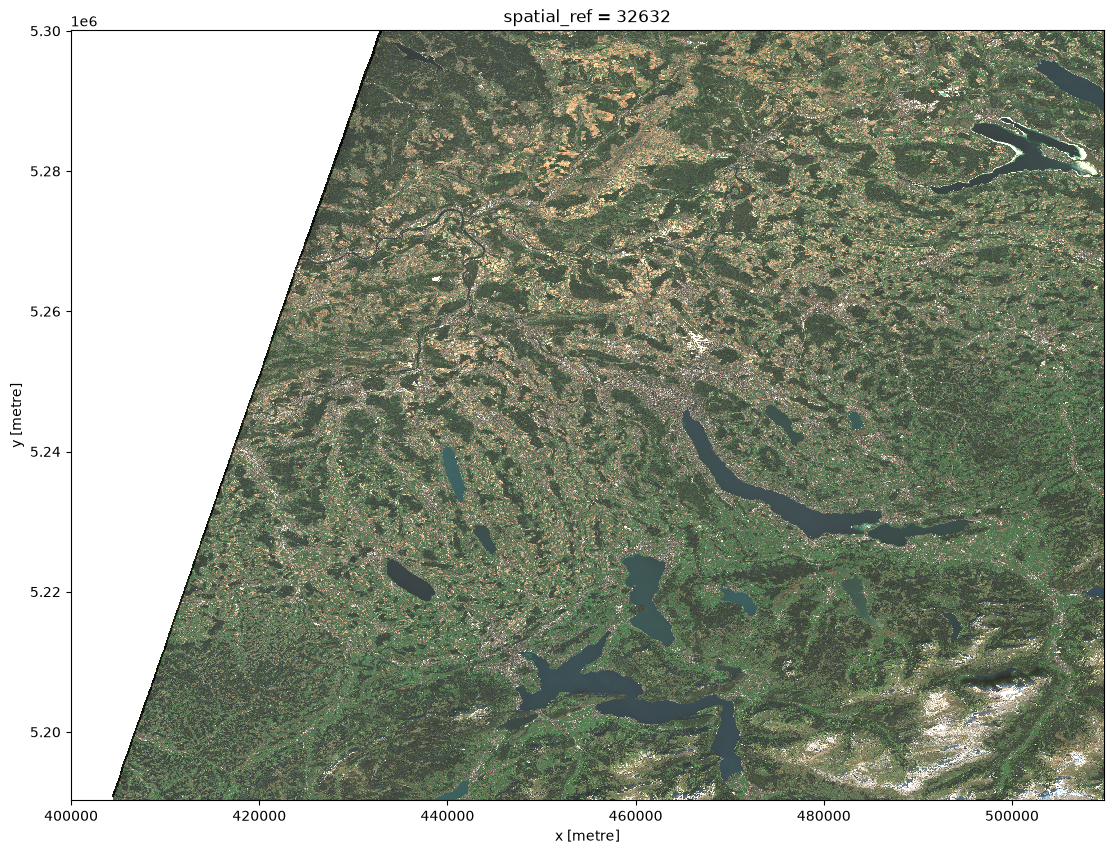

In [39]:
(
    mosaic
    .to_array(dim="band")
    .pipe(lambda x: x / 15000)
    .where(lambda x: x > 0.01)
    .plot.imshow(size=10, vmin=0.03, vmax=0.2)
)
